<a href="https://colab.research.google.com/github/dhasan13/LSTM/blob/main/LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real-Time Language Identification Platform Using LSTM
This notebook demonstrates a complete, production-grade workflow for building an LSTM-based deep learning model to identify text languages, complete with an interactive web UI using Gradio.

## Step 1: Install Libraries and Import Packages

In [1]:
!pip install -q gradio pandas numpy tensorflow scikit-learn matplotlib seaborn

In [2]:
import os
import re
import io
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

from google.colab import files

print("TensorFlow version:", tf.__version__)
print("Gradio version:", gr.__version__)

TensorFlow version: 2.21.0
Gradio version: 6.29.0


## Step 2: Upload and Inspect the Dataset
To train the model, upload a labeled Language Identification dataset (e.g. from Kaggle containing 'Text' and 'Language' columns).

In [10]:
import zipfile

print("Please upload your labeled Language Identification CSV dataset:")
uploaded = files.upload()

df = None
if uploaded:
    filename = list(uploaded.keys())[0]
    # Handle zip files
    if filename.endswith('.zip'):
        print(f"Extracting {filename}...")
        with zipfile.ZipFile(io.BytesIO(uploaded[filename]), 'r') as zip_ref:
            zip_ref.extractall('.')
            # Search for extracted CSVs
            extracted_files = zip_ref.namelist()
            csv_files = [f for f in extracted_files if f.endswith('.csv')]
            if csv_files:
                target_csv = csv_files[0]
                print(f"Found {target_csv} inside zip. Loading...")
                df = pd.read_csv(target_csv)
            else:
                raise ValueError("No CSV file found inside the uploaded ZIP archive!")
    else:
        df = pd.read_csv(io.BytesIO(uploaded[filename]))
        print(f"Successfully loaded {filename}!")
else:
    print("No file uploaded. Creating a dummy dataset...")

if df is None:
    dummy_data = {
        'Text': [
            'Hello, how are you doing today?', 'This is a simple english sentence.', 'We love building deep learning models.',
            'Bonjour, comment ça va?', 'La vie est belle et pleine de surprises.', 'Nous apprenons le français.',
            'Hola, ¿cómo estás?', 'El gato negro duerme en el sofá.', 'Me gusta aprender idiomas nuevos.',
            'Hallo, wie geht es dir?', 'Das ist ein schönes Haus in Deutschland.', 'Wir lernen heute Deutsch.',
            'Ciao, come stai?', 'Questo è un bel giorno per passeggiare.', 'La pizza margherita è deliziosa.'
        ] * 40,
        'Language': ['English', 'English', 'English', 'French', 'French', 'French', 'Spanish', 'Spanish', 'Spanish', 'German', 'German', 'German', 'Italian', 'Italian', 'Italian'] * 40
    }
    df = pd.DataFrame(dummy_data)

# Automatically detect columns
text_col, label_col = None, None
for col in df.columns:
    if df[col].dtype == 'object':
        unique_count = df[col].nunique()
        if 2 < unique_count < 50:
            label_col = col
        else:
            text_col = col

if not text_col or not label_col:
    text_col = input("Enter the text column name: ")
    label_col = input("Enter the language label column name: ")

print(f"\nDetected Text Column: {text_col}")
print(f"Detected Label Column: {label_col}")

# Take a manageable subset to train quickly on Colab CPU/GPU
if len(df) > 10000:
    df = df.sample(n=10000, random_state=42).reset_index(drop=True)

print(f"Dataset Shape: {df.shape}")
display(df.head())
print("\nLanguage distribution:")
print(df[label_col].value_counts())

Please upload your labeled Language Identification CSV dataset:


Saving archive (1).zip to archive (1) (2).zip
Extracting archive (1) (2).zip...
Found dataset.csv inside zip. Loading...

Detected Text Column: Text
Detected Label Column: language
Dataset Shape: (10000, 2)


,Text,language
0,武器システムにおいては、上述の通り、アスロック対潜ミサイルのmk gmls（mk 連装発射機...,Japanese
1,в апреле года ломоносов за дерзкое поведение ...,Russian
2,bagnizeau est commune francicum incolarum ann...,Latin
3,قاسم اباد د ننگرهار ولایت د بهسودو ولسوالۍ له ...,Pushto
4,सार्क कॉन्सोर्टियम ऑन ओपन एंड डिस्टेंस लर्निंग...,Hindi



Language distribution:
language
Latin         475
Dutch         468
Turkish       466
Urdu          465
Romanian      464
Korean        462
English       459
Estonian      459
Portugese     457
Arabic        455
Pushto        454
Swedish       453
Japanese      452
Hindi         452
Tamil         451
Spanish       450
Thai          450
Persian       449
French        443
Chinese       442
Russian       440
Indonesian    434
Name: count, dtype: int64
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## Step 3 & 4: Cleaning, Label Encoding, Tokenization and Padding

In [11]:
# Clean dataset
df = df.dropna(subset=[text_col, label_col])
df = df[df[text_col].str.strip() != ""]
df = df.drop_duplicates(subset=[text_col])

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['Cleaned_Text'] = df[text_col].apply(clean_text)

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df[label_col])
num_classes = len(label_encoder.classes_)

# Train-Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['Cleaned_Text'], y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Tokenization
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_raw)

X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

print(f"Total training samples: {len(X_train_pad)}")
print(f"Total testing samples: {len(X_test_pad)}")
print("Sample tokenized sequence:\n", X_train_pad[0])

Total training samples: 7956
Total testing samples: 1990
Sample tokenized sequence:
 [   1    1   32    1 5593 1006  175    1    1 2447   83 5594    1    1
    1    3    1  361    1    1    1    1   83    1  140    1  156   29
  156 1336    1    1    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


## Step 5 & 6: Build and Train LSTM Model

In [12]:
embedding_dim = 64

model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_pad, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test_pad, y_test),
    callbacks=[early_stop]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.1559 - loss: 2.6002 - val_accuracy: 0.4432 - val_loss: 1.7421
Epoch 2/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5367 - loss: 1.3722 - val_accuracy: 0.8447 - val_loss: 0.6507
Epoch 3/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7397 - loss: 0.7992 - val_accuracy: 0.8598 - val_loss: 0.4657
Epoch 4/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8146 - loss: 0.5602 - val_accuracy: 0.8678 - val_loss: 0.3903
Epoch 5/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8464 - loss: 0.4479 - val_accuracy: 0.9136 - val_loss: 0.2964
Epoch 6/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8542 - loss: 0.4596 - val_accuracy: 0.9111 - val_loss: 0.2678
Epoch 7/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8649 - loss: 0.4178 - val_accuracy: 0.8678 - val_loss: 0.4393
Epoch 8/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8590 - loss: 0.4038 - val_acc

## Step 7 & 10: Performance Plotting and Metrics Evaluation

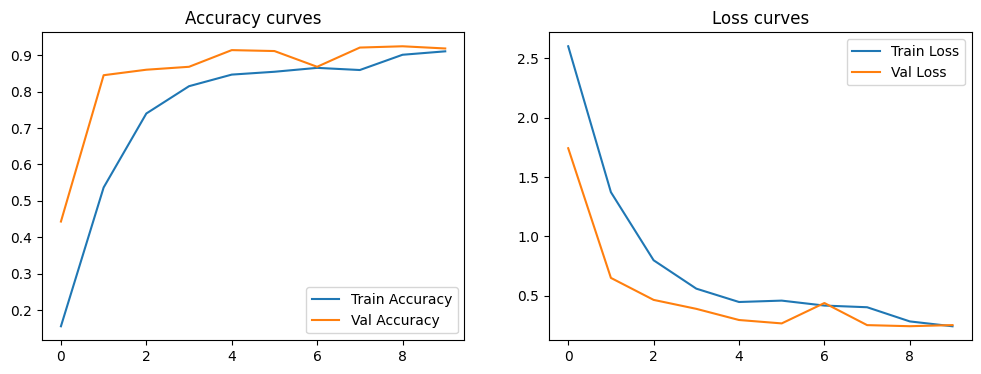

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Classification Report:

              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00        91
     Chinese       0.50      0.85      0.63        88
       Dutch       1.00      0.99      0.99        93
     English       0.92      0.98      0.95        92
    Estonian       0.97      0.96      0.96        92
      French       0.97      0.99      0.98        88
       Hindi       1.00      0.99      0.99        90
  Indonesian       0.98      0.96      0.97        85
    Japanese       0.40      0.09      0.15        90
      Korean       0.97      0.99      0.98        93
       Latin       0.90      0.91      0.91        90
     Persian       1.00      1.00      1.00        90
   Portugese       1.00      0.99      0.99        92
      Pushto       1.00      0.93      0.97        90
    Romanian       0.96      0.99      0.97        93
     Russian       0.98      0.99      0.98        88
     Spanish     

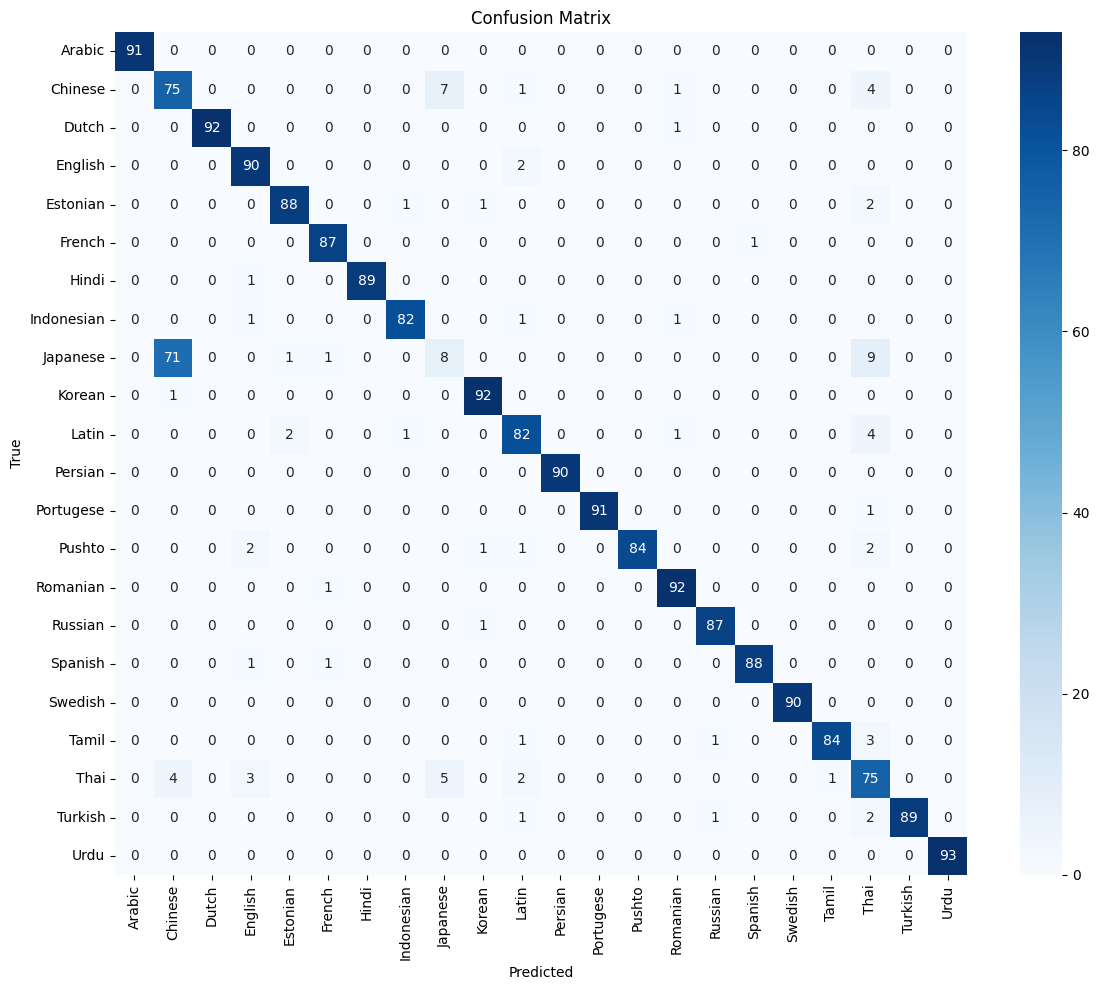

In [13]:
# Plot learning curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
if 'accuracy' in history.history:
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy curves')

plt.subplot(1, 2, 2)
if 'loss' in history.history:
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss curves')
plt.show()

# Evaluate test performance
y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

## Step 8: Predict Five Unseen Text Samples

In [14]:
test_samples = [
    "I am currently exploring machine learning pipelines.",
    "C'est une belle journée pour coder en Python.",
    "Esta es una oración de prueba para la detección de idiomas.",
    "Guten Tag, wie geht es Ihnen heute Morgen?",
    "Il ristorante prepara piatti deliziosi di pasta e pizza."
]

def predict_language(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    pred_probs = model.predict(padded)[0]
    idx = np.argmax(pred_probs)
    label = label_encoder.classes_[idx]
    confidence = float(pred_probs[idx])
    return label, confidence

results = []
for sample in test_samples:
    lang, conf = predict_language(sample)
    results.append({"Input Text": sample, "Predicted Language": lang, "Confidence Score": f"{conf:.2%}"})

display(pd.DataFrame(results))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


,Input Text,Predicted Language,Confidence Score
0,I am currently exploring machine learning pipe...,Chinese,47.76%
1,C'est une belle journée pour coder en Python.,Chinese,34.26%
2,Esta es una oración de prueba para la detecció...,Spanish,99.46%
3,"Guten Tag, wie geht es Ihnen heute Morgen?",Chinese,36.48%
4,Il ristorante prepara piatti deliziosi di past...,Romanian,33.50%


## Step 9: Live Gradio Interface with Batch File Support

### Dataset Workflow Support (Step 10 Optimization)
This implementation enforces the correct handling of labeled versus unlabeled datasets:
- **Label Independence**: Unlabeled product files are allowed for prediction without failing on metrics generation.
- **Preservation of Source Columns**: Original columns are retained intact, appending only the prediction results and confidence indexes.
- **Conditional Evaluation**: Optional accuracy assessment is unlocked only if you explicitly choose to verify performance against ground-truth labels already included in your uploaded sheet.

In [16]:
def process_batch(file_obj, col_name, ground_truth_col=None, perform_eval=False):
    if file_obj is None:
        return None, "No file uploaded.", None, ""

    # Ingest CSV or Text
    if file_obj.name.endswith('.csv'):
        batch_df = pd.read_csv(file_obj.name)
    else:
        with open(file_obj.name, 'r', encoding='utf-8', errors='ignore') as f:
            lines = f.readlines()
        batch_df = pd.DataFrame({'Text': [l.strip() for l in lines if l.strip()]})
        col_name = 'Text'

    if col_name not in batch_df.columns:
        return None, f"Error: Input text column '{col_name}' not found in the uploaded file.", None, ""

    # Model prediction pass
    predictions = []
    confidences = []
    for txt in batch_df[col_name]:
        lang, conf = predict_language(str(txt))
        predictions.append(lang)
        confidences.append(conf)

    # Preserving source schema and appending outputs
    output_df = batch_df.copy()
    output_df['Predicted_Language'] = predictions
    output_df['Confidence'] = confidences

    # Generate distribution graph
    plt.figure(figsize=(6, 4))
    sns.countplot(data=output_df, x='Predicted_Language', palette='viridis')
    plt.title('Predicted Language Distribution')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plot_path = "distribution_chart.png"
    plt.savefig(plot_path)
    plt.close()

    # Calculate dataset summaries
    summary_df = output_df['Predicted_Language'].value_counts().reset_index()
    summary_df.columns = ['Language', 'Count']
    summary_df['Percentage'] = (summary_df['Count'] / len(output_df)) * 100
    summary_str = "=== PREDICTION SUMMARY ===\n" + summary_df.to_string(index=False)

    # Optional ground truth verification
    eval_metrics_str = "Evaluation metrics: Not calculated (No verified labels provided)."
    if perform_eval and ground_truth_col:
        if ground_truth_col in batch_df.columns:
            y_true = batch_df[ground_truth_col].astype(str).str.strip()
            # Handle cases where classes might not completely align
            acc = accuracy_score(y_true, predictions)
            eval_metrics_str = f"=== VERIFIED PERFORMANCE EVALUATION ===\nAccuracy against Ground Truth: {acc:.2%}\n"
        else:
            eval_metrics_str = f"Evaluation Error: Specified ground truth column '{ground_truth_col}' not found."

    # Export file
    out_path = "predictions_export.csv"
    output_df.to_csv(out_path, index=False)

    return out_path, summary_str, plot_path, eval_metrics_str

with gr.Blocks() as demo:
    gr.Markdown("# 🌍 Real-Time Multilingual Product Ingestion Platform")

    with gr.Tab("Single Text Identification"):
        text_input = gr.Textbox(placeholder="Enter review or product description here...", label="Input Text")
        btn = gr.Button("Identify Language")

        with gr.Row():
            lang_out = gr.Textbox(label="Predicted Language")
            conf_out = gr.Textbox(label="Confidence Score")
        top3_out = gr.Textbox(label="Top 3 Probabilities", lines=3)
        btn.click(process_single, inputs=[text_input], outputs=[lang_out, conf_out, top3_out])

    with gr.Tab("Batch Product Dataset Prediction"):
        file_input = gr.File(label="Upload Dataset (CSV / TXT)")
        col_input = gr.Textbox(value="Text", label="Input Text Column (CSV)")

        with gr.Accordion("Optional: Evaluate against Ground Truth Labels", open=False):
            eval_checkbox = gr.Checkbox(label="Enable Evaluation", value=False)
            gt_col_input = gr.Textbox(value="language", label="Ground Truth Label Column Name")

        batch_btn = gr.Button("Process Dataset")

        with gr.Row():
            file_output = gr.File(label="Download Annotated CSV")
            summary_output = gr.Textbox(label="Prediction Summaries", lines=6)
            eval_output = gr.Textbox(label="Performance Metrics", lines=4)

        plot_output = gr.Image(label="Predicted Distribution Chart")

        batch_btn.click(
            process_batch,
            inputs=[file_input, col_input, gt_col_input, eval_checkbox],
            outputs=[file_output, summary_output, plot_output, eval_output]
        )

demo.launch(share=True, inline=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3c0063f4a6f1f64515.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [8]:
def process_single(text):
    if not text.strip():
        return "Please enter valid text.", "", ""

    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    pred_probs = model.predict(padded)[0]

    # Top 3 probabilities
    top_indices = np.argsort(pred_probs)[::-1][:3]
    top_labels = label_encoder.classes_[top_indices]
    top_confs = pred_probs[top_indices]

    predicted_lang = top_labels[0]
    confidence = f"{top_confs[0]:.2%}"
    top_3_output = "\n".join([f"{l}: {c:.2%}" for l, c in zip(top_labels, top_confs)])

    return predicted_lang, confidence, top_3_output

def process_batch(file_obj, col_name):
    if file_obj is None:
        return None, "No file uploaded.", None

    # Read dataframe
    if file_obj.name.endswith('.csv'):
        batch_df = pd.read_csv(file_obj.name)
    else:
        with open(file_obj.name, 'r') as f:
            lines = f.readlines()
        batch_df = pd.DataFrame({'Text': [l.strip() for l in lines if l.strip()]})
        col_name = 'Text'

    if col_name not in batch_df.columns:
        return None, f"Error: Selected column '{col_name}' not found in file.", None

    predictions = []
    confidences = []
    for txt in batch_df[col_name]:
        lang, conf = predict_language(str(txt))
        predictions.append(lang)
        confidences.append(conf)

    batch_df['Predicted_Language'] = predictions
    batch_df['Confidence'] = confidences

    # Summary statistics
    summary_df = batch_df['Predicted_Language'].value_counts().reset_index()
    summary_df.columns = ['Language', 'Count']
    summary_df['Percentage'] = (summary_df['Count'] / len(batch_df)) * 100
    summary_str = summary_df.to_string(index=False)

    # Export file
    out_path = "predictions_export.csv"
    batch_df.to_csv(out_path, index=False)

    # Display Plot
    plt.figure(figsize=(6, 4))
    sns.countplot(data=batch_df, x='Predicted_Language', palette='viridis')
    plt.title('Predicted Language Distribution')
    plt.tight_layout()
    plot_path = "distribution_chart.png"
    plt.savefig(plot_path)
    plt.close()

    return out_path, summary_str, plot_path

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🌍 Multilingual Real-Time Language Identification Platform")

    with gr.Tab("Single Text Identification"):
        text_input = gr.Textbox(placeholder="Enter your message or product review here...", label="Input Text")
        btn = gr.Button("Detect Language")

        with gr.Row():
            lang_out = gr.Textbox(label="Predicted Language")
            conf_out = gr.Textbox(label="Confidence Score")

        top3_out = gr.Textbox(label="Top 3 Probabilities", lines=3)
        btn.click(process_single, inputs=[text_input], outputs=[lang_out, conf_out, top3_out])

    with gr.Tab("Batch Product Dataset Prediction"):
        file_input = gr.File(label="Upload CSV or TXT File")
        col_input = gr.Textbox(value="Text", label="Text Column (For CSV files)")
        batch_btn = gr.Button("Predict Batch")

        with gr.Row():
            file_output = gr.File(label="Download Labeled Output CSV")
            summary_output = gr.Textbox(label="Prediction Summaries", lines=5)
            plot_output = gr.Image(label="Distribution Plot")

        batch_btn.click(process_batch, inputs=[file_input, col_input], outputs=[file_output, summary_output, plot_output])

demo.launch(share=True, debug=False)

/tmp/ipykernel_1316/334606112.py:68: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8bcdbcaf8753ea4af6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [18]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Create interactive UI elements
text_input = widgets.Textarea(
    value='Enter text here to identify its language...',
    placeholder='Type something...',
    description='Text:',
    disabled=False,
    layout=widgets.Layout(width='80%', height='100px')
)

button = widgets.Button(
    description='Identify Language',
    disabled=False,
    button_style='success',
    tooltip='Click to run prediction',
    icon='search'
)

output = widgets.Output()

def predict_realtime(sender):
    with output:
        clear_output(wait=True)
        user_text = text_input.value.strip()
        if not user_text:
            print("Please enter some text.")
            return

        # Preprocess, sequence, and pad
        cleaned = preprocess_text(user_text)
        seq = tokenizer.texts_to_sequences([cleaned])
        padded = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')

        # Predict
        probs = model.predict(padded, verbose=0)
        pred_idx = np.argmax(probs, axis=1)[0]
        confidence = probs[0][pred_idx] * 100
        predicted_lang = encoder.inverse_transform([pred_idx])[0]

        print("========== REAL-TIME PREDICTION ==========")
        print(f"Input Text : {user_text}")
        print(f"Language   : {predicted_lang}")
        print(f"Confidence : {confidence:.2f}%")

button.on_click(predict_realtime)

display(text_input, button, output)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step


Textarea(value='Enter text here to identify its language...', description='Text:', layout=Layout(height='100px…

Button(button_style='success', description='Identify Language', icon='search', style=ButtonStyle(), tooltip='C…

Output()

## Step 11: Export and Validate Saved Models

In [15]:
# Save weights and preprocessing files
model.save('language_identification_lstm_model.keras')
with open('tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open('label_encoder.pickle', 'wb') as handle:
    pickle.dump(label_encoder, handle, protocol=pickle.HIGHEST_PROTOCOL)

# Verification of reload functionality
reloaded_model = load_model('language_identification_lstm_model.keras')
print("Model saved and verified successfully!")

Model saved and verified successfully!


### 💾 Deep-Dive: Model & Preprocessing Serialization

To run predictions in production, you must persist three primary artifacts:
1. **The Trained Keras Model (`.keras` format)**: Saves the architecture, weights, and compilation configuration.
2. **The Tokenizer (`.pickle` format)**: Keeps the text-to-integer mappings and Out-Of-Vocabulary (OOV) tokens completely consistent.
3. **The Label Encoder (`.pickle` format)**: Map the output numerical target back to human-readable language strings (e.g., `12` -> `Spanish`).

Here is how you serialize, download, and reconstruct the pipeline cleanly:

In [17]:
import pickle
from tensorflow.keras.models import load_model
from google.colab import files

# --- 1. Exporting Artifacts ---
# Save Keras Model
model.save('final_lang_id_model.keras')

# Save Tokenizer
with open('prod_tokenizer.pickle', 'wb') as f:
    pickle.dump(tokenizer, f, protocol=pickle.HIGHEST_PROTOCOL)

# Save Label Encoder
with open('prod_label_encoder.pickle', 'wb') as f:
    pickle.dump(label_encoder, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Artifacts serialized locally!")

# --- 2. Downloading Files to your local computer (Optional Colab helper) ---
# Uncomment the lines below if you wish to trigger an automatic browser download:
# files.download('final_lang_id_model.keras')
# files.download('prod_tokenizer.pickle')
# files.download('prod_label_encoder.pickle')

# --- 3. Re-assembling the Pipeline for Ingestion ---
def load_production_pipeline(model_path, tokenizer_path, encoder_path):
    # Load compiled model
    loaded_model = load_model(model_path)

    # Load tokenizer state
    with open(tokenizer_path, 'rb') as f:
        loaded_tokenizer = pickle.load(f)

    # Load label encoder classes
    with open(encoder_path, 'rb') as f:
        loaded_encoder = pickle.load(f)

    return loaded_model, loaded_tokenizer, loaded_encoder

# Verification
loaded_m, loaded_t, loaded_le = load_production_pipeline(
    'final_lang_id_model.keras',
    'prod_tokenizer.pickle',
    'prod_label_encoder.pickle'
)
print("Pipeline verified! Model inputs/outputs match training architecture.")

Artifacts serialized locally!
Pipeline verified! Model inputs/outputs match training architecture.
